# TokenGate inference: original implementation and vLLM

[TokenGate](https://arxiv.org/abs/2610.26754) learns which prompt tokens to keep for the later model layers. This notebook uses the released Qwen3 and Qwen3.5 checkpoints to retrieve a fact hidden in a long text.

In this notebook, we'll compare the original TokenGate implementation with vLLM at $K=64$, $K=512$, $K=2{,}048$, $K=4{,}096$, $K=8{,}192$, and **All**. $K$ counts retained tokens from the text; instructions and the question stay protected. **All** keeps every token while still applying TokenGate's learned attention adjustments.

We'll also compare latency with pretrained Qwen running in vLLM without TokenGate.

Sections 2–4 walk through one example. Section 5 evaluates the full 184-example test split to compare retrieval accuracy against latency.

## 1. Set up

Use Linux with an idle CUDA GPU, CUDA PyTorch, and the installed [TokenGate vLLM fork](https://github.com/luis-gasparschroeder/vllm/tree/lgs/tokengate). From the TokenGate repository root, install the notebook dependencies and build its attention kernel:

```bash
uv pip install --python .venv/bin/python -e '.[benchmark]' ipykernel matplotlib-inline
.venv/bin/python kernels/fa2bias/build.py
```

Set `VLLM_SOURCE` to the vLLM checkout and `GPU` to the device you want to use. If the attention kernel is already built for your PyTorch/CUDA environment, set `FA2BIAS_SITE` to that build instead. Both checkpoints are public; no Hugging Face token is needed.

In [1]:
import os
from datetime import datetime, timezone
from pathlib import Path
from runpy import run_path

ROOT = Path.cwd().resolve()
if ROOT.name == "examples":
    ROOT = ROOT.parent
os.chdir(ROOT)
helpers = run_path(str(ROOT / "examples/inference-vllm-helper.py"))

VLLM_SOURCE = Path(os.environ.get("VLLM_SOURCE", str(ROOT.parent / "vllm"))).resolve()
GPU = "0"
N_EXAMPLES = 1
WARMUPS = 2
REPEATS = 5
PROFILE = False  # Capture an extra, untimed full-context trace per implementation.
ENGINES = ["original", "vllm", "vllm_tiled", "vllm_base", "vllm_base_triton"]
CONFIGS = [
    ROOT / "benchmarks/configs/vllm_niah_qwen3.yaml",
    ROOT / "benchmarks/configs/vllm_niah_qwen3_5.yaml",
]
RUNTIME = {"vllm_source": VLLM_SOURCE, "gpu": GPU}

# Optional: a JSON list of completed run directories; unset to run inference.
SAVED_RUNS = helpers["saved_run_paths"]("TOKEN_GATE_SAVED_RUNS")
OUTPUT = (
    SAVED_RUNS[0].parent if SAVED_RUNS
    else ROOT / "results/vllm-benchmark" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ")
)

### Check the hardware

The next cell reports the CPU, memory, GPU, and software configuration used for inference.

In [2]:
helpers["show_hardware"](SAVED_RUNS, GPU)

              Inference hardware: Qwen3-1.7B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 0                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

              Inference hardware: Qwen3.5-2B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 1                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

## 2. Inspect the checkpoints and example

Each released checkpoint contains a **gate**, which scores prompt tokens, and a **LoRA adapter**, which stores learned updates to Qwen's weights. TokenGate inference uses both. Qwen3 places the gate after layer 1; Qwen3.5 uses layer 3, counting from zero.

We'll use a 32K needle-in-a-haystack example. The question appears before the text so the gate can use it when choosing tokens. Increase `N_EXAMPLES` to include more of the five examples provided with the repository.

In [3]:
helpers["show_checkpoints"](CONFIGS)
sample = helpers["show_example"](ROOT / "examples/data/niah_32k_samples.jsonl", N_EXAMPLES)

                                       Published checkpoints                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Gate layer ┃ Checkpoint                         ┃ Budgets                           ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 1          │ liana313/tokengate-niah-qwen3-1.7b │ 64, 512, 2,048, 4,096, 8,192, All │
│ Qwen3.5-2B │ 3          │ liana313/tokengate-niah-qwen3.5-2b │ 64, 512, 2,048, 4,096, 8,192, All │
└────────────┴────────────┴────────────────────────────────────┴───────────────────────────────────┘

Question: What is the best thing to do in San Francisco?

Expected answer: eat a sandwich and sit in Dolores Park on a sunny day

Text preview: People who worry about the increasing gap between rich and poor generally look back on the mid twentieth century as a golden 
age. In those days we had a large number of high-paying union manufacturing jobs that boosted the median income. I wouldn't quite call the 
high-paying union job a myth, but I think people who dwell on it are reading too much into it. Oddly enough, it was working with startups 
that made me realize where the high-paying union job came from. In a rapidly growing market, you d...

## 3. Run inference

The benchmark tokenizes each sample once per model. All implementations receive those exact token IDs and the same prunable span, $[s,e)$. Only tokens in that span compete for the $K$ places.

[The runner](../benchmarks/run_vllm_benchmark.py) contains the full calls and matched EOS settings; [the vLLM implementation](../benchmarks/vllm_backend.py) sets up the supported engine configuration. Each model is loaded once per implementation. Warmups are excluded from the results. The original worker also checks that enabling streaming leaves the output tokens and retained positions unchanged.

In [4]:
runs = helpers["run_benchmarks"](
    CONFIGS, OUTPUT, saved_runs=SAVED_RUNS, engines=ENGINES,
    n=N_EXAMPLES, warmups=WARMUPS, repeats=REPEATS, profile=PROFILE,
    **RUNTIME,
)

qwen3: loaded 20 settings, 2 warmup(s), 5 timing repetitions.

qwen35: loaded 20 settings, 2 warmup(s), 5 timing repetitions.

Using saved measurements; inference will not run again.

## 4. Compare the answers

We compare five implementations:

| Implementation | Model setup | Full attention |
| --- | --- | --- |
| **Original TokenGate** | Qwen with the trained gate and LoRA adapter, using the original TokenGate code | TokenGate's FlashAttention-2 kernels |
| **TokenGate in vLLM (Triton)** | The same trained gate and LoRA updates, using vLLM | Triton with TokenGate's learned attention adjustments |
| **TokenGate in vLLM (tiled prefill)** | The same trained gate and LoRA updates, using vLLM | Custom Triton prefill with the learned bias; Triton paged attention during generation |
| **Base Qwen in vLLM (auto)** | Pretrained Qwen, without the gate or LoRA updates | Backend selected by vLLM |
| **Base Qwen in vLLM (Triton)** | Pretrained Qwen, without the gate or LoRA updates | Triton |

The three TokenGate implementations run at $K=64$, $K=512$, $K=2{,}048$, $K=4{,}096$, $K=8{,}192$, and **All**. The two Base Qwen baselines keep every prompt token and do not apply TokenGate's learned attention adjustments.

Compare each answer with the expected phrase. A correct score means the answer contains that phrase after normalization. Different wrong answers receive the same score, so check the text as well as the score.

In [5]:
helpers["show_answers"](runs, sample["id"], ENGINES)

                                                        Answers to the same question                                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Answer                                                   ┃ Correct ┃ Cap reached ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 64   │ eat a sandwich and sit on the puppet theater parkway on  │ no      │ no          │
│            │                                   │      │ a sunny day                                              │         │             │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 5

Qwen3-1.7B, original versus Triton: Generated tokens match at every tested budget.

Qwen3-1.7B, Triton versus tiled prefill: generated tokens match.

Qwen3.5-2B, original versus Triton: Generated tokens differ for at least one tested budget.

Qwen3.5-2B, Triton versus tiled prefill: generated tokens match.

## 5. Measure the latency–accuracy trade-off

We now evaluate **all 184 held-out 32K examples** at each budget, using the same five implementations. The 16 validation examples are excluded.

**Time to first token (TTFT)** measures the time from submitting the prepared input tokens to receiving the first generated token. **Time to final token** ends when the last token arrives. Downloads, model loading, and warmup runs are excluded.

Grouped bars compare these two latencies. **Speed-up sits above each pruned bar; retrieval accuracy sits directly below it**, in an aligned row. The multiplier compares latency with the faster base-Qwen backend for that model; the dashed line marks that baseline. For example, **2.0×** means half the baseline latency. The Base Qwen bars appear at **K=All** because they process the full prompt.

For each example, we measure latency three times after a warmup and take the median. Bar heights show the median across examples; accuracy counts each example once. The numerical table includes 95% bootstrap intervals for latency and Wilson intervals for accuracy. If repeats disagree, an example counts as correct only when every repeat is correct.

This takes longer than the single-example run. The next cell prepares the full pool with the repository's existing NIAH generator, checks it against the published examples, and selects the reserved test IDs.

In [6]:
TEST_SAVED_RUNS = helpers["saved_run_paths"]("TOKEN_GATE_TEST_RUNS")
TEST_OUTPUT = TEST_SAVED_RUNS[0].parent if TEST_SAVED_RUNS else OUTPUT / "heldout"
TEST_SAMPLES = Path(os.environ.get(
    "TOKEN_GATE_TEST_SAMPLES",
    str(ROOT / "datasets/niah_kamradt/niah_kamradt_32k.jsonl"),
)).resolve()
test_ids = helpers["niah_test_ids"]()
test_configs = (
    helpers["prepare_niah_configs"](CONFIGS, TEST_SAMPLES, TEST_OUTPUT)
    if not TEST_SAVED_RUNS else []
)

Test split: 184 examples; 16 validation examples excluded.

In [7]:
test_runs = helpers["run_benchmarks"](
    test_configs, TEST_OUTPUT, saved_runs=TEST_SAVED_RUNS, engines=ENGINES,
    split="test", warmups=1, repeats=3, **RUNTIME,
)

qwen3-0: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-1: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-2: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-3: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-0: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-1: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-2: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-3: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

Using saved measurements; inference will not run again.

                             Held-out retrieval and first-token latency (95% intervals)                             
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Correct ┃ Accuracy             ┃ TTFT (ms)               ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 129.4 [129.3, 129.6]    │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 129.6 [129.3, 129.7]    │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 146.8 [146.6, 146.9]    │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 199.2 [199.0, 199.4]    │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 307.4 [307.3, 307.6]    │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 1317.1 [1315.3, 1321.3] │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 91.9 [91.8, 92.1]       │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 101.0 [100.8, 101.1]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 136.9 [136.7, 137.1]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 204.9 [204.7, 205.0]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 413.3 [413.1, 413.6]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 3618.2 [3608.9, 3623.8] │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 91.6 [91.5, 91.7]       │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 100.0 [99.9, 100.1]     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 126.2 [126.0, 126.3]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 164.3 [164.1, 164.5]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 259.5 [259.4, 259.7]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 1230.2 [1229.0, 1232.0] │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ 182/184 │ 98.9% [96.1, 99.7]   │ 1073.2 [1071.2, 1075.0] │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ 182/184 │ 98.9% [96.1, 99.7]   │ 2373.2 [2366.3, 2377.9] │
│ Qwen3.5-2B │ Original TokenGate                │ 64   │ 170/184 │ 92.4% [87.6, 95.4]   │ 189.1 [188.8, 189.2]    │
│ Qwen3.5-2B │ Original TokenGate                │ 512  │ 176/184 │ 95.7% [91.7, 97.8]   │ 189.3 [189.1, 189.6]    │
│ Qwen3.5-2B │ Original TokenGate                │ 2048 │ 183/184 │ 99.5% [97.0, 99.9]   │ 201.8 [201.6, 202.0]    │
│ Qwen3.5-2B │ Original TokenGate                │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 246.6 [246.5, 247.0]    │
│ Qwen3.5-2B │ Original TokenGate                │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 331.7 [331.5, 331.8]    │
│ Qwen3.5-2B │ Original TokenGate                │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 920.7 [919.4, 922.0]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 64   │ 170/184 │ 92.4% [87.6, 95.4]   │ 119.6 [119.4, 119.9]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 512  │ 176/184 │ 95.7% [91.7, 97.8]   │ 126.4 [126.1, 126.5]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 2048 │ 183/184 │ 99.5% [97.0, 99.9]   │ 148.8 [148.6, 149.1]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 181.0 [180.8, 181.3]    │
│ Qwen3.5-2B │ TokenGa

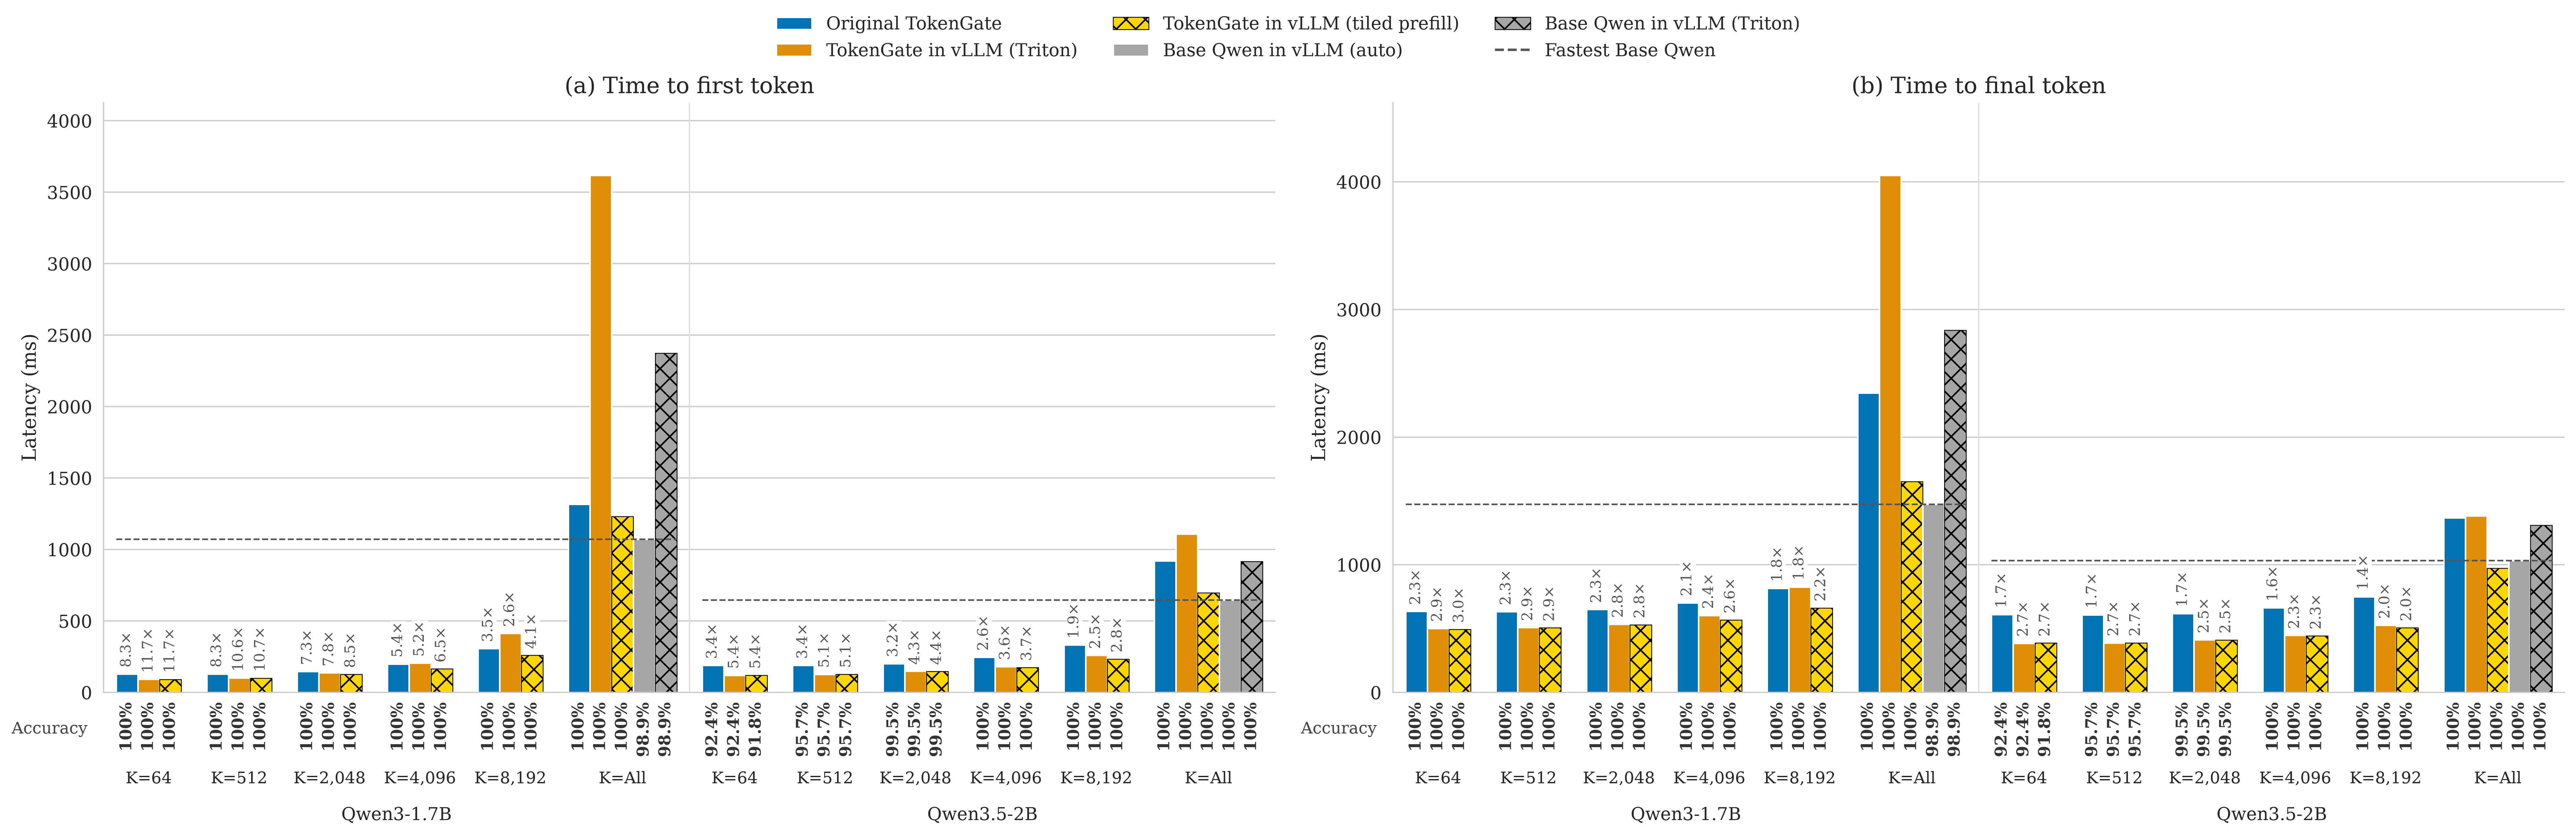

In [8]:
tradeoff = helpers["load_tradeoff"](test_runs, test_ids)
helpers["show_test_results"](tradeoff, CONFIGS, ENGINES, TEST_OUTPUT)
helpers["show_comparison"](tradeoff, TEST_OUTPUT / "latency-accuracy")